# Replicate scatter of EPMA reference-material analyses versus the reported error

**Question:** In the 85 replicate EPMA analyses of reference material 7802 Apatite, does the reported `errpct` match the observed replicate scatter for each element?

**Data:** `data/EMPA_Apatite_Standards.csv` from the USGS data release "Apatite and monazite geochemistry data at Mountain Pass, California, 2024" (Benson and Watts), https://doi.org/10.5066/P1LGUGBG, accessed 2026-11-03, CC0.

**Data and code availability:** the data are committed in `data/` exactly as downloaded, and the original release is at the DOI above. This notebook reads only `data/EMPA_Apatite_Standards.csv`. It runs from top to bottom in the course environment rebuilt from `pyproject.toml` and `uv.lock`, and it downloads nothing.

## Parameters

**Purpose:** keep every label and every number that encodes a choice in one place, so that later cells use the same values.

**Scientific choice:** `MIN_DETECTION_FRACTION` is 1.0, so an element is used only if it is detected in all of the replicate analyses. The data blank a value below the detection limit, so a partly detected element would leave only its detected values, which truncates the scatter and biases the mean upward. The labels are constants so that a change in the file's wording is fixed in one line.

**Expected output:** none; the cell only defines constants.

In [1]:
DATA_PATH = "data/EMPA_Apatite_Standards.csv"  # path relative to the notebook's folder
STANDARD_LABEL = "7802 Apatite"  # value of `Sample` for the replicate analyses of the reference material
DETECTION_LIMIT_LABEL = "Detection Limit"  # value of `Sample` for the row that holds the detection limits
MIN_DETECTION_FRACTION = 1.0  # fraction of the replicate analyses (no unit) in which an element must be detected; blanks below the detection limit truncate the scatter
NOT_MEASURED_COLUMNS = ["O", "Total"]  # `O` is calculated and `Total` is a sum (data dictionary), so neither is a measured element
HISTOGRAM_BINS = 10  # bins per histogram (no unit); about the square root of the 85 replicates
ERRPCT_COVERAGE_FACTOR = 1  # no unit; errpct is read as a relative 1-sigma error, because the data dictionary and the paper do not define it
ALTERNATIVE_COVERAGE_FACTOR = 2  # no unit; errpct read as a 2-sigma (95 %) error, shown as a sensitivity
CONFIDENCE_LEVEL = 0.95  # no unit; two-sided level of every interval, not adjusted for the seven elements
OUTLIER_Z_THRESHOLD = 3.5  # standard deviations from the mean; about a 4 % chance that 85 normal values hold a point this far out
N_RESAMPLES = 10000  # bootstrap resamples; the interval ends moved by about 0.02 between seeds in a check
RANDOM_SEED = 527  # arbitrary fixed seed, so the bootstrap intervals repeat exactly

## Load the data

**Purpose:** load the file from its relative path and separate the replicate analyses from the detection-limit row.

**What one row is:** one replicate EPMA analysis of the reference material `7802 Apatite`, except one row that holds the detection limit of each element. Units: `*_wtpct` is weight percent, `*_errpct` is percent (the data dictionary says only "Error of ... analysis, percent"), and `*_TDI` is percent (time-dependent intensity correction).

**Scientific choice:** the `Detection Limit` row is not a measurement, so it is kept apart and never enters the replicate scatter. Any row with another label would be reported, not silently dropped.

**Expected output:** 86 rows in the file, of which 85 are replicate analyses and 1 is the detection-limit row, and 0 rows with any other label.

In [2]:
import pandas as pd

data = pd.read_csv(DATA_PATH)
is_detection_limit = data["Sample"] == DETECTION_LIMIT_LABEL
is_replicate = data["Sample"] == STANDARD_LABEL

detection_limits = data[is_detection_limit].iloc[0]  # wt% for *_wtpct columns, one value per column
replicates = data[is_replicate].reset_index(drop=True)  # one row per replicate analysis

print(f"{len(data)} rows in the file: {len(replicates)} replicate analyses of {STANDARD_LABEL}, {is_detection_limit.sum()} detection-limit row")
print(f"rows with any other label: {(~is_detection_limit & ~is_replicate).sum()}")

86 rows in the file: 85 replicate analyses of 7802 Apatite, 1 detection-limit row
rows with any other label: 0


## Detections per element

**Purpose:** count, for each element, how many of the 85 replicate analyses have a reported `*_wtpct` value, and let code pick the elements that pass `MIN_DETECTION_FRACTION`.

**Scientific choice:** a blank `*_wtpct` means the analysis was below the detection limit, so "detected" means "not blank". `O` and `Total` are not measured elements and are left out of the candidates. The same table also counts the `*_errpct` values that are reported and the ones that are negative, because a negative error percent cannot be an error and would break any comparison with scatter.

**Expected output:** a table with one row per candidate element (Ce, Mn, Ca, Sr, Ba, Na, P, S, Cl, F), then the elements used and the elements excluded. The elements Ce, Ca, Sr, Na, P, S and F should be detected 85 of 85 times and Mn, Ba and Cl fewer times; negative `errpct` values should appear only in elements that are excluded.

In [3]:
candidate_elements = [
    col.removesuffix("_wtpct")
    for col in replicates.columns
    if col.endswith("_wtpct") and col.removesuffix("_wtpct") not in NOT_MEASURED_COLUMNS
]

detection_table = pd.DataFrame(
    {
        "n_detected": [replicates[f"{el}_wtpct"].notna().sum() for el in candidate_elements],  # count of replicates with a wt% value
        "detection_limit_wtpct": [detection_limits[f"{el}_wtpct"] for el in candidate_elements],  # wt%
        "n_errpct_reported": [replicates[f"{el}_errpct"].notna().sum() for el in candidate_elements],  # count
        "n_errpct_negative": [(replicates[f"{el}_errpct"] < 0).sum() for el in candidate_elements],  # count
    },
    index=candidate_elements,
)
detection_table["detection_fraction"] = detection_table["n_detected"] / len(replicates)  # no unit
detection_table["used"] = detection_table["detection_fraction"] >= MIN_DETECTION_FRACTION

elements_used = detection_table.index[detection_table["used"]].tolist()
elements_excluded = detection_table.index[~detection_table["used"]].tolist()

print(detection_table.to_string())
print(f"elements used: {elements_used}")
print(f"elements excluded: {elements_excluded}")

    n_detected  detection_limit_wtpct  n_errpct_reported  n_errpct_negative  detection_fraction   used
Ce          85                  0.077                 85                  0            1.000000   True
Mn          32                  0.025                 85                  6            0.376471  False
Ca          85                  0.061                 85                  0            1.000000   True
Sr          85                  0.061                 85                  0            1.000000   True
Ba           2                  0.317                 85                 38            0.023529  False
Na          85                  0.012                 85                  0            1.000000   True
P           85                  0.021                 85                  0            1.000000   True
S           85                  0.009                 85                  0            1.000000   True
Cl           5                  0.009                 85                 

**Problems found on loading, and what was done about each:**

- **Blank cells.** A blank `*_wtpct` means the value was below the detection limit, so blanks were left as missing values and not replaced by zero or by the detection limit, which would invent a number that was not measured.
- **Detections per element.** Ce, Ca, Sr, Na, P, S and F were detected in all 85 analyses and are used; Mn (32 of 85), Cl (5 of 85) and Ba (2 of 85) were detected too rarely, because the replicates that remain would be only the high values and would understate the scatter, so they are excluded by `MIN_DETECTION_FRACTION`.
- **Negative `errpct`.** Negative values appear only in the excluded elements (Mn 6, Cl 30, Ba 38), and none appear in the seven used elements, so nothing was removed or corrected; the excluded elements also report an `errpct` for all 85 analyses even where no value was detected, which shows that their `errpct` is not a meaningful error.
- **The `Detection Limit` row and the non-measured columns.** The detection-limit row was kept apart from the replicates, and `O` (calculated) and `Total` (a sum) were left out of the candidate elements.

These data cannot say what `errpct` measures, because the original data dictionary defines it only as "Error of ... analysis, percent": reading it as a 2-sigma error instead of a 1-sigma error would doubles every R (Sr goes from 0.91 to 1.83), so whether the reported error matches the scatter depends on a definition the data do not give.

## Descriptive statistics

**Purpose:** summarize the replicates of each used element in one table: n, mean, standard deviation, relative standard deviation (RSD), minimum and maximum, plus the median and a robust RSD.

**Scientific choice:** the robust RSD is the median absolute deviation (scaled by 1.4826 so that it equals the standard deviation for a normal distribution) divided by the median. It is added next to the ordinary RSD to show how much one or two extreme points inflate the standard deviation; the ordinary RSD is still the one used in the comparison with `errpct`.

**Expected output:** one row per used element (Ce, Ca, Sr, Na, P, S, F). `mean`, `median`, `sd`, `min` and `max` are in weight percent and the two RSD columns are in percent. Ca and P should have an RSD below 2 %, Ce an RSD of about 21 %, and S should have a robust RSD smaller than its ordinary RSD.

In [4]:
from scipy import stats

stat_rows = {}
for el in elements_used:
    x = replicates[f"{el}_wtpct"]  # wt%, all 85 replicates
    stat_rows[el] = {
        "n": x.count(),
        "mean_wtpct": x.mean(),  # wt%
        "median_wtpct": x.median(),  # wt%
        "sd_wtpct": x.std(ddof=1),  # wt%, sample standard deviation
        "rsd_pct": 100 * x.std(ddof=1) / x.mean(),  # %
        "robust_rsd_pct": 100 * stats.median_abs_deviation(x, scale="normal") / x.median(),  # %
        "min_wtpct": x.min(),  # wt%
        "max_wtpct": x.max(),  # wt%
    }
descriptive_table = pd.DataFrame(stat_rows).T
descriptive_table["n"] = descriptive_table["n"].astype(int)
print(descriptive_table.round(4).to_string())

     n  mean_wtpct  median_wtpct  sd_wtpct  rsd_pct  robust_rsd_pct  min_wtpct  max_wtpct
Ce  85      0.3122        0.3048    0.0663  21.2471         22.9808     0.1897     0.5049
Ca  85     38.7953       38.8108    0.7262   1.8720          1.6388    37.0250    40.8937
Sr  85      0.4023        0.4041    0.0415  10.3211         11.1384     0.3248     0.5175
Na  85      0.2086        0.2069    0.0103   4.9292          4.6702     0.1802     0.2363
P   85     17.9118       17.9508    0.2991   1.6699          1.8253    17.1140    18.5676
S   85      0.1908        0.1916    0.0139   7.2882          5.8421     0.1365     0.2268
F   85      3.6734        3.6493    0.3590   9.7723          9.4560     2.6682     4.6703


## Figure 1: reported `errpct` against the measured value

**Purpose:** plot, for each used element, the reported `errpct` of every replicate against its own `wtpct`, to see whether `errpct` is one fixed number per element or changes from row to row.

**Scientific choice:** the Spearman rank correlation is printed because it does not assume a straight line. A strong negative value means the analyses with lower measured values carry a larger relative error, which would mean `errpct` has to be summarized (or applied row by row) before it is compared with the scatter.

**Expected output:** a grid of seven panels with one hollow circle per replicate, and a table of the Spearman correlation for each element; the correlations should be strongly negative.

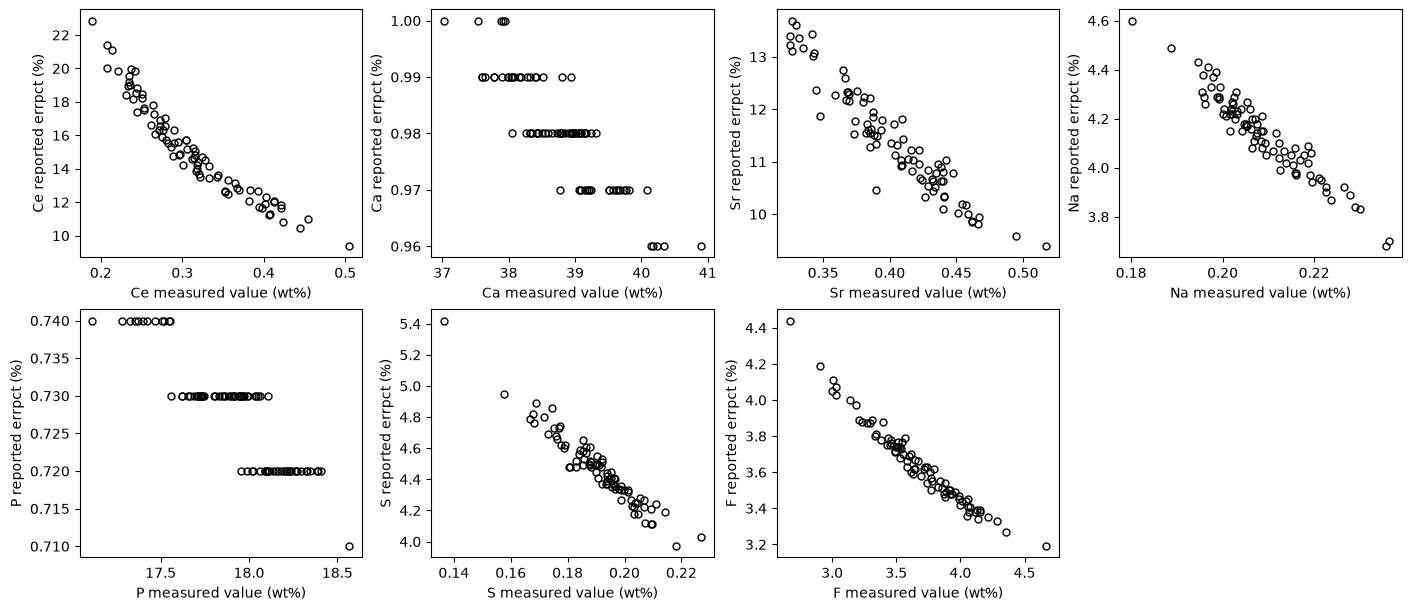

Ce   -0.98
Ca   -0.87
Sr   -0.95
Na   -0.95
P    -0.89
S    -0.96
F    -0.98


In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True)
correlation_rows = {}
for ax, el in zip(axes.flat, elements_used):
    x = replicates[f"{el}_wtpct"]  # wt%
    e = replicates[f"{el}_errpct"]  # %
    ax.plot(x, e, linestyle="none", marker="o", markerfacecolor="none", markeredgecolor="black", markersize=5)
    ax.set_xlabel(f"{el} measured value (wt%)")
    ax.set_ylabel(f"{el} reported errpct (%)")
    correlation_rows[el] = stats.spearmanr(x, e).statistic  # no unit
for ax in axes.flat[len(elements_used):]:
    ax.set_visible(False)
plt.show()

print(pd.Series(correlation_rows, name="spearman_rho_errpct_vs_wtpct").round(2).to_string())

In every used element the reported `errpct` falls as the measured value rises (Spearman correlation from -0.87 for Ca to -0.98 for Ce and F), so `errpct` is not one number per element but changes from row to row.

## Figure 2: distribution of each element's replicates

**Purpose:** plot a histogram of the 85 replicate values of each used element, and tabulate two numbers that the histograms hint at: the largest distance of any point from the mean in standard deviations, and the Shapiro-Wilk p-value for normality.

**Scientific choice:** `HISTOGRAM_BINS` sets the bin count. For 85 normal values the largest distance is usually about 2.5 to 3 standard deviations, so a value near 4 is a point to check against the raw data and not to delete; the standard deviation is later compared with `errpct` and one extreme point can move it.

**Expected output:** a grid of seven histograms with one panel per element, then a table with `max_abs_z` and `shapiro_p` per element. Ce should have the smallest `shapiro_p` and S the largest `max_abs_z`.

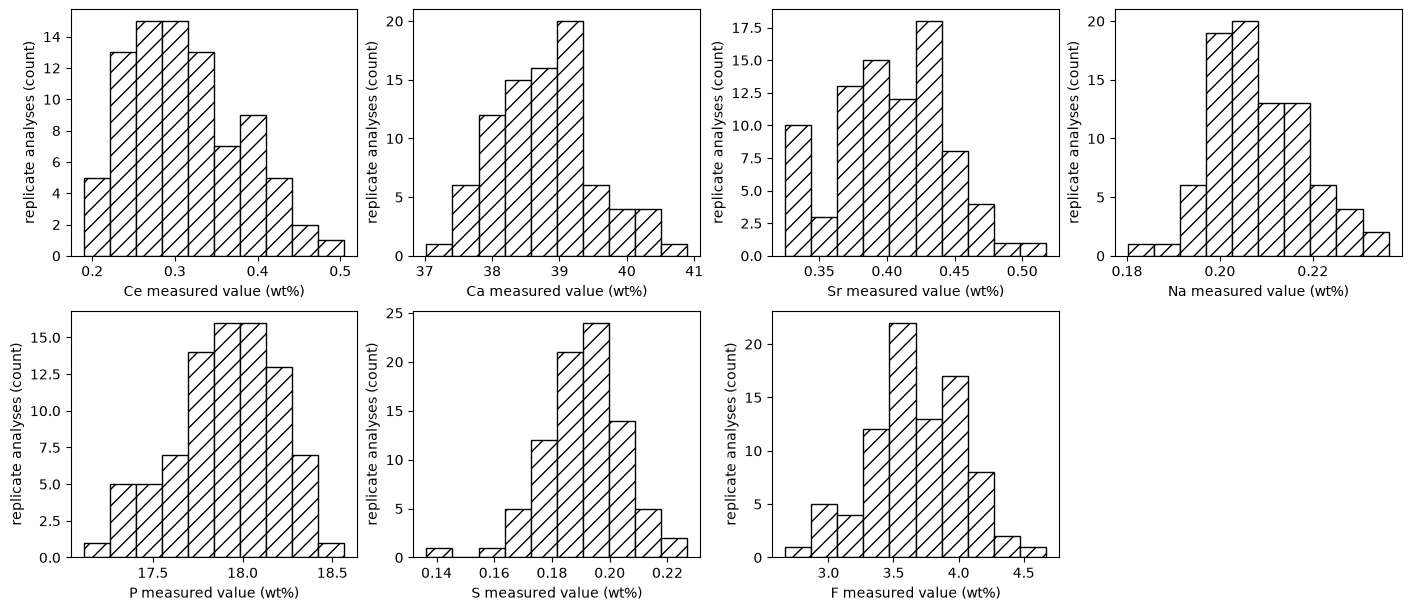

    max_abs_z  shapiro_p
Ce      2.906      0.037
Ca      2.889      0.635
Sr      2.773      0.249
Na      2.761      0.059
P       2.667      0.505
S       3.904      0.058
F       2.800      0.903


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6), constrained_layout=True)
normality_rows = {}
for ax, el in zip(axes.flat, elements_used):
    x = replicates[f"{el}_wtpct"]  # wt%
    ax.hist(x, bins=HISTOGRAM_BINS, facecolor="white", edgecolor="black", hatch="//")
    ax.set_xlabel(f"{el} measured value (wt%)")
    ax.set_ylabel("replicate analyses (count)")
    normality_rows[el] = {
        "max_abs_z": ((x - x.mean()) / x.std(ddof=1)).abs().max(),  # standard deviations
        "shapiro_p": stats.shapiro(x).pvalue,  # no unit
    }
for ax in axes.flat[len(elements_used):]:
    ax.set_visible(False)
plt.show()

print(pd.DataFrame(normality_rows).T.round(3).to_string())

S has the one point farthest from its mean (3.9 standard deviations), and Ce has the lowest Shapiro-Wilk p-value (0.037), but with seven tests one p-value below 0.05 is weak evidence of non-normality.

Figure 1 showed that `errpct` falls as the measured value rises in all seven elements (Spearman -0.87 to -0.98), so it is not one number per element, and this changed the plan: instead of comparing the standard deviation with an average errpct, each replicate's errpct is converted to an absolute error in wt% and the 85 errors are pooled as a root mean square before the comparison.

## First analysis: observed scatter against the reported error

**Purpose:** for each used element, compare the standard deviation of the 85 replicates with the error that `errpct` reports, as one ratio `R` with an interval.

**Scientific choice:** `errpct` is read as a relative 1-sigma error (`ERRPCT_COVERAGE_FACTOR`), so replicate i has an absolute error `sigma_i = value_i * errpct_i / 100` in wt%. Independent errors add as variances, so the 85 values are pooled as `sigma_reported = sqrt(mean(sigma_i**2))`, and `R = SD / sigma_reported`; R = 1 means the scatter equals the reported error and R > 1 means the scatter is larger. The interval is a bootstrap over replicate rows, which are the independent measurements, with each row's value and `errpct` drawn together; it needs no normality, and Ce is the least normal element (Shapiro-Wilk p = 0.037) and S has a point 3.9 standard deviations out. The chi-square interval for a standard deviation, which assumes normality, is shown beside it as a check. Every interval is 95 % for its own element and is not adjusted for there being seven. The direction is "above 1" or "below 1" when the bootstrap interval lies wholly on that side, and "contains 1" otherwise. The last column gives R if `errpct` were a 2-sigma error, which doubles R.

**Expected output:** one row per element with `R`, its bootstrap interval, the direction, the chi-square interval and the 2-sigma R. Ce, Ca, P, S and F should have intervals above 1, and Sr and Na should contain 1, with Na's lower end near 1.

In [7]:
import numpy as np


def reported_sigma(values, errpct, k):
    """Pooled reported error in wt%: the root mean square of each replicate's absolute error."""
    return np.sqrt(np.mean((values * errpct / 100 / k) ** 2))


def ratio(values, errpct, k):
    """Observed standard deviation divided by the pooled reported error (no unit)."""
    return values.std(ddof=1) / reported_sigma(values, errpct, k)


def bootstrap_interval(values, errpct, k, rng):
    """Percentile interval of R over replicate rows; a row's value and errpct are drawn together."""
    rows = rng.integers(0, len(values), size=(N_RESAMPLES, len(values)))  # row indices, with replacement
    v, e = values[rows], errpct[rows]
    r_boot = v.std(axis=1, ddof=1) / np.sqrt(np.mean((v * e / 100 / k) ** 2, axis=1))
    tail = 100 * (1 - CONFIDENCE_LEVEL) / 2  # percent in each tail
    return np.percentile(r_boot, [tail, 100 - tail])


def direction(low, high):
    """Where the interval of R lies against 1."""
    if low > 1:
        return "above 1"
    if high < 1:
        return "below 1"
    return "contains 1"


alpha = 1 - CONFIDENCE_LEVEL  # no unit
rng = np.random.default_rng(RANDOM_SEED)
result_rows = {}
for el in elements_used:
    x = replicates[f"{el}_wtpct"].to_numpy()  # wt%
    e = replicates[f"{el}_errpct"].to_numpy()  # %
    dof = len(x) - 1  # degrees of freedom of the standard deviation
    low, high = bootstrap_interval(x, e, ERRPCT_COVERAGE_FACTOR, rng)
    r_value = ratio(x, e, ERRPCT_COVERAGE_FACTOR)
    result_rows[el] = {
        "sd_wtpct": x.std(ddof=1),  # wt%
        "sigma_reported_wtpct": reported_sigma(x, e, ERRPCT_COVERAGE_FACTOR),  # wt%
        "R": r_value,
        "R_low": low,
        "R_high": high,
        "direction": direction(low, high),
        "R_chi2_low": r_value * np.sqrt(dof / stats.chi2.ppf(1 - alpha / 2, dof)),
        "R_chi2_high": r_value * np.sqrt(dof / stats.chi2.ppf(alpha / 2, dof)),
        "R_if_2sigma": ratio(x, e, ALTERNATIVE_COVERAGE_FACTOR),
    }
first_analysis = pd.DataFrame(result_rows).T
numeric_columns = [c for c in first_analysis.columns if c != "direction"]
first_analysis[numeric_columns] = first_analysis[numeric_columns].astype(float)
print(first_analysis.round({"sd_wtpct": 4, "sigma_reported_wtpct": 4, "R": 2, "R_low": 2, "R_high": 2, "R_chi2_low": 2, "R_chi2_high": 2, "R_if_2sigma": 2}).to_string())

    sd_wtpct  sigma_reported_wtpct     R  R_low  R_high   direction  R_chi2_low  R_chi2_high  R_if_2sigma
Ce    0.0663                0.0459  1.45   1.24    1.63     above 1        1.26         1.70         2.89
Ca    0.7262                0.3802  1.91   1.61    2.18     above 1        1.66         2.25         3.82
Sr    0.0415                0.0455  0.91   0.78    1.03  contains 1        0.79         1.08         1.83
Na    0.0103                0.0086  1.19   0.99    1.37  contains 1        1.04         1.40         2.39
P     0.2991                0.1303  2.30   1.96    2.60     above 1        1.99         2.70         4.59
S     0.0139                0.0085  1.64   1.30    1.97     above 1        1.42         1.93         3.28
F     0.3590                0.1332  2.70   2.26    3.10     above 1        2.34         3.17         5.39


## The flagged point and what it does to R

**Purpose:** find the replicate that lies farther than `OUTLIER_Z_THRESHOLD` standard deviations from the mean of any used element, show where it sits in the file, and recompute R without it.

**Scientific choice:** the point is flagged, not removed. The main result above keeps all 85 replicates, and the table here shows how far R and its direction move if the flagged row is dropped from every element; a statistical distance is not a reason to delete a measurement, and no record in the data says the analysis was faulty.

**Expected output:** one flagged point, in S, about 3.9 standard deviations below the mean, on file line 74, with its z-scores in the other elements; S's R should fall by about 9 % without it and the other elements' R should change by less than 5 %; every direction should stay the same except Sr, whose interval moves from containing 1 to lying below 1.

In [8]:
z_scores = pd.DataFrame(
    {el: (replicates[f"{el}_wtpct"] - replicates[f"{el}_wtpct"].mean()) / replicates[f"{el}_wtpct"].std(ddof=1) for el in elements_used}
)  # standard deviations from each element's mean
flagged_rows = (z_scores.abs() > OUTLIER_Z_THRESHOLD).any(axis=1)

for row in z_scores.index[flagged_rows]:
    file_line = data.index[is_replicate][row] + 2  # the header is line 1
    print(f"replicate {row}, file line {file_line}, z-scores: {z_scores.loc[row].round(2).to_dict()}")

kept = replicates[~flagged_rows]
rng_sensitivity = np.random.default_rng(RANDOM_SEED)
sensitivity_rows = {}
for el in elements_used:
    x_kept = kept[f"{el}_wtpct"].to_numpy()  # wt%
    e_kept = kept[f"{el}_errpct"].to_numpy()  # %
    low, high = bootstrap_interval(x_kept, e_kept, ERRPCT_COVERAGE_FACTOR, rng_sensitivity)
    r_kept = ratio(x_kept, e_kept, ERRPCT_COVERAGE_FACTOR)
    sensitivity_rows[el] = {
        "R_all": first_analysis.loc[el, "R"],
        "R_without_flagged": r_kept,
        "change_pct": 100 * (r_kept / first_analysis.loc[el, "R"] - 1),  # %
        "direction_without_flagged": direction(low, high),
    }
sensitivity = pd.DataFrame(sensitivity_rows).T
print(f"replicates kept: {len(kept)} of {len(replicates)}")
print(sensitivity.round({"R_all": 2, "R_without_flagged": 2, "change_pct": 1}).to_string())

replicate 71, file line 74, z-scores: {'Ce': -0.54, 'Ca': 1.77, 'Sr': 2.77, 'Na': 0.37, 'P': 1.66, 'S': -3.9, 'F': -2.8}
replicates kept: 84 of 85
       R_all R_without_flagged change_pct direction_without_flagged
Ce  1.446184           1.45201   0.402896                   above 1
Ca  1.910168          1.885635  -1.284354                   above 1
Sr  0.912665          0.875334  -4.090327                   below 1
Na  1.192508           1.19882   0.529255                contains 1
P   2.295212          2.270622  -1.071371                   above 1
S   1.637999          1.486757  -9.233311                   above 1
F   2.695305          2.577068  -4.386777                   above 1


## Figure 3: R for each element

**Purpose:** show R and its bootstrap interval for the seven elements against the line R = 1, with the value R would take if `errpct` were a 2-sigma error.

**Scientific choice:** the interval is drawn only for the 1-sigma reading, which is the stated assumption; the 2-sigma value is a hollow square without an interval, to show where the point would move and not to compete with the main result.

**Expected output:** a plot with one row per element, a filled circle with horizontal bars for R, a hollow square for the 2-sigma R, and a dashed vertical line at 1.

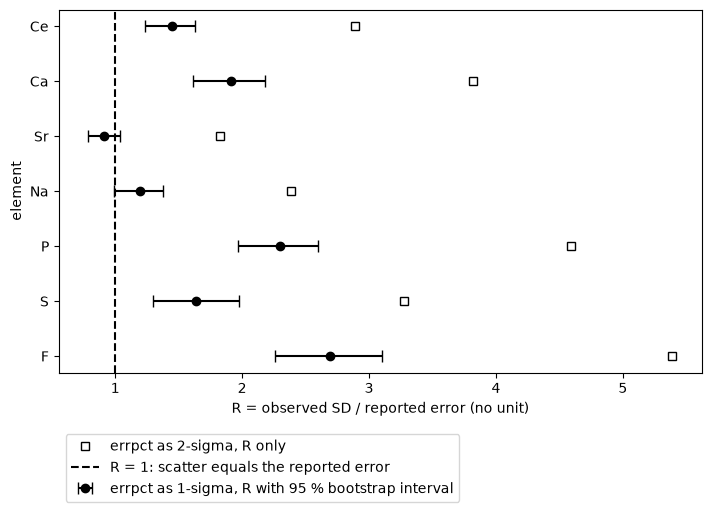

In [9]:
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
y_positions = np.arange(len(elements_used))[::-1]  # first element at the top
r_values = first_analysis["R"].to_numpy()
ax.errorbar(
    r_values,
    y_positions,
    xerr=[r_values - first_analysis["R_low"].to_numpy(), first_analysis["R_high"].to_numpy() - r_values],
    fmt="o",
    color="black",
    capsize=4,
    label="errpct as 1-sigma, R with 95 % bootstrap interval",
)
ax.plot(
    first_analysis["R_if_2sigma"].to_numpy(),
    y_positions,
    linestyle="none",
    marker="s",
    markerfacecolor="none",
    markeredgecolor="black",
    label="errpct as 2-sigma, R only",
)
ax.axvline(1, linestyle="--", color="black", label="R = 1: scatter equals the reported error")
ax.set_yticks(y_positions)
ax.set_yticklabels(elements_used)
ax.set_xlabel("R = observed SD / reported error (no unit)")
ax.set_ylabel("element")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.15))
plt.show()

For Ce, Ca, P, S and F the bootstrap interval lies wholly above 1 (R from 1.45 for Ce to 2.70 for F), so the replicate scatter is larger than the reported error, while Sr (R = 0.91) and Na (R = 1.19) have intervals that contain 1; each interval is for its own element and is not adjusted for the seven.

The bootstrap interval treats the 85 replicates as independent, and if the rows follow the order of measurement, drift would add to the standard deviation and could be part of why R is above 1 for five elements (1.45 to 2.70); next, each element's value will be plotted against row number and its lag-1 autocorrelation computed, and the independence assumption is kept only if no trend or correlation appears.

## Versions

**Purpose:** record the Python and package versions that ran the notebook, and which Python it was.

**Scientific choice:** none; the path of the Python executable shows that the notebook ran in this project's `.venv`.

**Expected output:** the Python version and path, then the versions of numpy, pandas, scipy and matplotlib.

In [10]:
import platform
import sys
from importlib.metadata import version

print(f"Python {platform.python_version()} at {sys.executable}")
for package in ["numpy", "pandas", "scipy", "matplotlib"]:
    print(f"{package} {version(package)}")

Python 3.14.7 at c:\Users\minsu\chem527\chem527-project\.venv\Scripts\python.exe
numpy 2.5.3
pandas 3.0.6
scipy 1.18.1
matplotlib 3.11.2
